# Exploratory Data Analysis

## Roles to Explore

In [1]:
#Import libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

#Load dataset
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

#Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

## Filter for UK Data Analyst Roles

In [2]:
df_uk = df[(df['job_country'] == 'United Kingdom') & (df['job_title_short'] == 'Data Analyst')]
df_uk.head(3)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
74,Data Analyst,Data Entry/Economic Data Analyst,"Worcester, UK",via BeBee,Full-time,False,United Kingdom,2023-11-01 13:11:18,False,False,United Kingdom,NaN,NaN,NaN,ttgTalentSolutions,"[sql, r, python, tableau, power bi]","{'analyst_tools': ['tableau', 'power bi'], 'pr..."
97,Data Analyst,"Systems & Data Analyst - Exploitation, Missing...",United Kingdom,via Totaljobs,Full-time and Contractor,False,United Kingdom,2023-12-04 13:14:01,True,False,United Kingdom,NaN,NaN,NaN,Solihull Metropolitan Borough Council,NaN,NaN
170,Data Analyst,Projects & Solutions Data Analyst (UK Pensions),"Birmingham, UK",via LinkedIn,Full-time,False,United Kingdom,2023-01-04 13:35:45,False,False,United Kingdom,NaN,NaN,NaN,Aon,"[sql, excel]","{'analyst_tools': ['excel'], 'programming': ['..."


## Analyse Job Location

In [3]:
#Firstly, remove locations as "United Kingdom" as it is too vague
#use replace to remove ", UK" from strings
df_loc = df_uk[df_uk['job_location'] != 'United Kingdom'].replace(', UK', '', regex=True)

#Then filter for the top 10 job locations
df_loc = df_loc['job_location'].value_counts().head(10).to_frame()


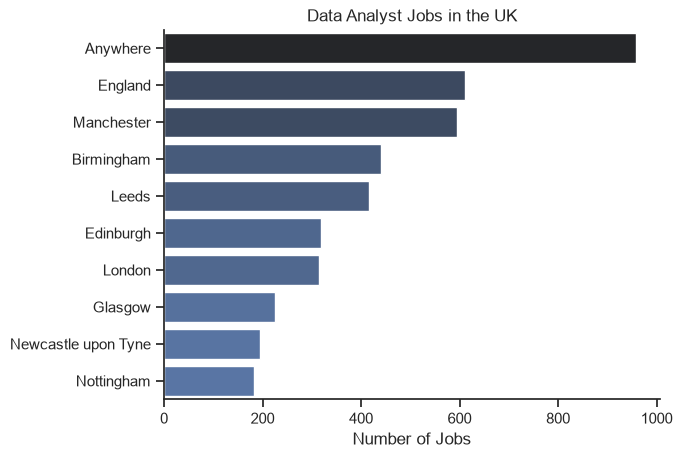

In [4]:
sns.set_theme(style='ticks')
sns.barplot(data = df_loc,
            y = 'job_location',
            x = 'count',
            hue = 'count',
            palette='dark:b_r',
            legend=False)
sns.despine() #remove plot border

plt.title('Data Analyst Jobs in the UK')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.show()

## Job Requirements & Perks

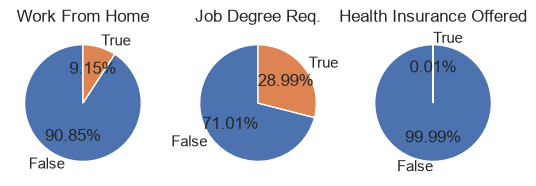

In [10]:
#call the plot
fig, ax = plt.subplots(1,3)

#define a dictionary of the column names and the title we want to give it
dict_col = {
    'job_work_from_home': 'Work From Home',
    'job_no_degree_mention': 'Job Degree Req.',
    'job_health_insurance': 'Health Insurance Offered'
}

#Using a for loop to cycle through multiple plots
#because we're calling from a dictionary, we have to pass variables (col,title) as a tuple
#enumerate lets us cycle through the items of dict_col using i
for i, (col, title) in enumerate(dict_col.items()):
    ax[i].pie(df_uk[col].value_counts(), startangle=90, autopct='%1.2f%%', labels = ['False','True'])
    ax[i].set_title(title)
    
plt.show()

## Companies

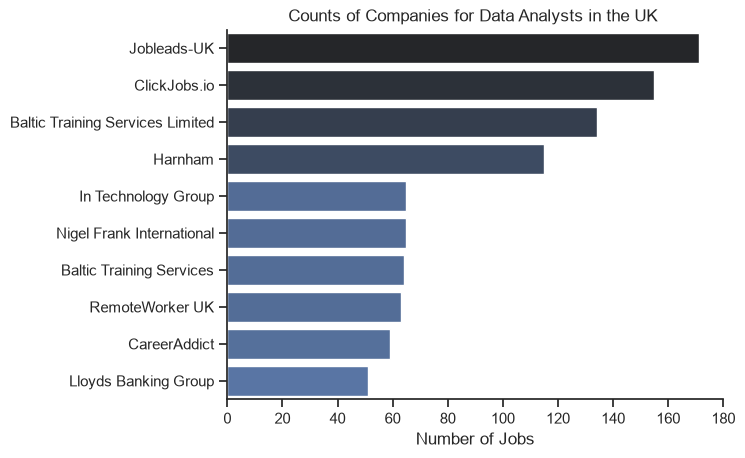

In [21]:
#Subset the Data by company
df_comp = df_uk['company_name'].value_counts().head(10).to_frame()

sns.set_theme(style='ticks')
sns.barplot(data = df_comp,
            y = 'company_name',
            x = 'count',
            hue = 'count',
            palette='dark:b_r',
            legend=False)
sns.despine() #remove plot border

plt.title('Counts of Companies for Data Analysts in the UK ')
plt.xlabel('Number of Jobs')
plt.ylabel('')
plt.xlim(0,180)
plt.show()